# 07b — Study B: Adding Steering Winds (GRU)

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric sections:** Model Training, Model Evaluation

In notebook 07a, the steering winds from the NCEP/NCAR reanalysis cut XGBoost's test error by 14 km,
from 152 to 138 km. Now we put the same question to the project's best neural network, the round 2 GRU
from notebook 06:

> *Does the GRU gain as much from the winds as the trees did, and with winds, which model comes out ahead?*

Everything about the experiment carries over from 07a: the same 56,434 forecasts, the same Study B split
(train 1980–2004, validation 2005–2008, test 2009–2013), and the same 14 steering features, read from the
file 07a saved. The GRU keeps exactly its round 2 settings. Nothing is re-tuned, so any difference comes
from the winds alone.

| | |
|---|---|
| **Inputs** | `tracks_clean.csv.gz`, `steering_features.csv.gz` and `preds_studyb_xgb.csv` (from 07a), `models/round2_config.json` |
| **Outputs** | `data/processed/preds_studyb_gru.csv`, `models/studyb_gru_*`, figures `fig27`–`fig29` |

### Setting things up

Here, the imports match notebook 06: PyTorch and the project's `rnn.py`, with training on the Apple GPU (MPS)
and CPU work capped at 4 threads. XGBoost stays out of this session; its results come in from 07a's saved
file instead.

In [1]:
# Imports and paths
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.windows import (build_samples, build_sequences, persistence_displacement, track_error_km,
                                to_latlon, TARGET_COLS, STEP_FEATURES, STATIC_COLS)
from stormtrack.steering import STEERING_COLS
from stormtrack.rnn import RNNForecaster, train_model, predict

FIG_DIR, MODEL_DIR = ROOT / "reports" / "figures", ROOT / "models"
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CFG = json.loads((MODEL_DIR / "round2_config.json").read_text())
SEEDS = CFG["seeds"]
print(f"PyTorch {torch.__version__} | training on: {DEVICE}")
print("Round 2 GRU settings:", {k: CFG[k] for k in ("cell", "n_steps", "hidden", "layers", "dropout", "lr",
                                                    "weight_decay", "batch_size")})

pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

PyTorch 2.15.0 | training on: mps
Round 2 GRU settings: {'cell': 'gru', 'n_steps': 7, 'hidden': 256, 'layers': 2, 'dropout': 0.29899104316725633, 'lr': 0.000902040696761779, 'weight_decay': 0.00017882217310984675, 'batch_size': 1024}


## 1. Rebuilding the Study B forecasts

First, we rebuild the forecast samples and attach the steering features saved by 07a, matching on storm
segment and time. The check at the end makes sure every Study B forecast found its features, and that the
split sizes match 07a exactly.

In [2]:
tracks = load_clean()
S_all = build_samples(tracks)
kw = dict(keep_default_na=False, na_values=[""], parse_dates=["ISO_TIME"])     # keep basin code "NA" as text
steer = pd.read_csv(PROCESSED / "steering_features.csv.gz", **kw)
S = S_all.merge(steer[["SEG_ID", "ISO_TIME", "split_b"] + STEERING_COLS], on=["SEG_ID", "ISO_TIME"], how="inner")
assert len(S) == len(steer) and S[STEERING_COLS].notna().all().all()

BASINS = sorted(S_all["BASIN"].unique())
for b in BASINS:
    S[f"basin_{b}"] = (S["BASIN"] == b).astype(float)
assert CFG["static_features"] == STATIC_COLS + [f"basin_{b}" for b in BASINS]
S.groupby("split_b").agg(samples=("SID", "size"), storms=("SID", "nunique")).reindex(["train", "val", "test"])

,samples,storms
split_b,,
train,46896,2194
val,5514,343
test,4024,241


Next come the network inputs. The GRU reads the storm's last 7 steps (42 hours) one at a time, and gets the
"static" information, the facts about the forecast as a whole, through a side door straight into its output
layers. Since the steering winds describe the situation at the forecast time, they join the static features,
so the GRU now has 12 static inputs without winds and 26 with them.

Within the helper below, everything is scaled exactly as in notebook 06. Statistics come from the Study B training
seasons only, padding stays at zero, and the target is the correction to persistence.

In [3]:
is_tr, is_va, is_te = (S["split_b"].eq(p).to_numpy() for p in ("train", "val", "test"))
SEQ = build_sequences(tracks, S, n_steps=CFG["n_steps"])
P = persistence_displacement(S)
Y = S[TARGET_COLS].to_numpy() - P
FEATURE_SETS = {"tracks only": CFG["static_features"], "tracks + winds": CFG["static_features"] + STEERING_COLS}

real = SEQ[is_tr][..., -1] == 1
mu, sd = SEQ[is_tr][real].mean(0), SEQ[is_tr][real].std(0)
mu[-1], sd[-1] = 0.0, 1.0
SEQ_SC = np.where(SEQ[..., -1:] == 1, (SEQ - mu) / sd, 0.0).astype(np.float32)
y_sc = Y[is_tr].std(0)

def tensors(static_cols):
    st = S[static_cols].to_numpy(dtype=float)
    s_mu, s_sd = st[is_tr].mean(0), st[is_tr].std(0)
    s_sd[s_sd == 0] = 1.0
    st = ((st - s_mu) / s_sd).astype(np.float32)
    t = lambda m: (torch.tensor(SEQ_SC[m]), torch.tensor(st[m]), torch.tensor(Y[m] / y_sc, dtype=torch.float32))
    return {"train": t(is_tr), "val": t(is_va), "test": t(is_te)}

T = {label: tensors(cols) for label, cols in FEATURE_SETS.items()}
for label, t in T.items():
    print(f"{label:>15s}: sequences {tuple(t['train'][0].shape)}, static {tuple(t['train'][1].shape)}")

    tracks only: sequences (46896, 7, 5), static (46896, 12)
 tracks + winds: sequences (46896, 7, 5), static (46896, 26)


## 2. Training the GRU with and without winds

Now the training itself. For each feature set, we train the round 2 GRU with the same three seeds as
before (42, 7 and 2024), early-stopped on the Study B validation seasons, and average the three into an
ensemble. That's six networks in all, which takes a few minutes on the laptop. The cell prints one line per
network.

In [4]:
va, te = S[is_va].reset_index(drop=True), S[is_te].reset_index(drop=True)
P_va, P_te = P[is_va], P[is_te]
disp = {label: {"val": [], "test": []} for label in FEATURE_SETS}
runs = []
t_all = time.time()
for label, cols in FEATURE_SETS.items():
    for seed in SEEDS:
        t0 = time.time()
        torch.manual_seed(seed)
        model = RNNForecaster(len(STEP_FEATURES), len(cols), cell=CFG["cell"], hidden=CFG["hidden"],
                              layers=CFG["layers"], dropout=CFG["dropout"])
        model, hist = train_model(model, T[label]["train"], T[label]["val"], y_sc, DEVICE, seed=seed, lr=CFG["lr"],
                                  weight_decay=CFG["weight_decay"], batch_size=CFG["batch_size"], verbose=False)
        torch.save(model.state_dict(), MODEL_DIR / f"studyb_gru_{label.replace(' + ', '_').replace(' ', '_')}_seed{seed}.pt")
        for part, P_part in (("val", P_va), ("test", P_te)):
            disp[label][part].append(predict(model, T[label][part][0], T[label][part][1], DEVICE) * y_sc + P_part)
        e = track_error_km(va, disp[label]["val"][-1]).mean()
        runs.append({"features": label, "seed": seed, "val_mean_km": e, "epochs": len(hist)})
        print(f"{label:>15s}, seed {seed:4d}: validation {e:6.1f} km after {len(hist):2d} epochs ({time.time() - t0:.0f} s)")
print(f"All six networks trained in {(time.time() - t_all) / 60:.1f} minutes")
pd.DataFrame(runs).groupby("features")["val_mean_km"].agg(["mean", "min", "max"]).round(1)

    tracks only, seed   42: validation  138.7 km after 34 epochs (39 s)


    tracks only, seed    7: validation  138.3 km after 32 epochs (38 s)


    tracks only, seed 2024: validation  138.4 km after 31 epochs (34 s)


 tracks + winds, seed   42: validation  127.9 km after 26 epochs (29 s)


 tracks + winds, seed    7: validation  127.5 km after 31 epochs (32 s)


 tracks + winds, seed 2024: validation  128.0 km after 35 epochs (37 s)
All six networks trained in 3.5 minutes


,mean,min,max
features,,,
tracks + winds,127.8,127.5,128.0
tracks only,138.5,138.3,138.7


So, the winds help the GRU just as clearly as they helped the trees. Without them, the three networks land at 138.3–138.7 km on the validation seasons; with them, at 127.5–128.0 km. The two groups don't even come close to overlapping, so the gain isn't an accident of one lucky seed. Training stays quick too, about half a minute per network, with early stopping kicking in after 26–35 epochs.

## 3. All of Study B side by side

Next, we bring in 07a's per-forecast errors for persistence and XGBoost, check that they line up forecast by
forecast with this notebook's, and add the two GRU ensembles. The cell below builds the summary table for
the validation seasons and then the one that matters most, for the test seasons.

In [5]:
xg = pd.read_csv(PROCESSED / "preds_studyb_xgb.csv", **kw)
xg_parts = {p: xg[xg["split_b"] == p].reset_index(drop=True) for p in ("val", "test")}
for p, data in (("val", va), ("test", te)):
    assert (xg_parts[p]["SEG_ID"].to_numpy() == data["SEG_ID"].to_numpy()).all()
    assert (xg_parts[p]["ISO_TIME"].to_numpy() == data["ISO_TIME"].to_numpy()).all()

errors = {}
for p, data in (("val", va), ("test", te)):
    x = xg_parts[p]
    errors[p] = {"Persistence": x["err_persistence_km"].to_numpy(),
                 "XGBoost, tracks only": x["err_xgboost_tracks_only_km"].to_numpy(),
                 "XGBoost, tracks + winds": x["err_xgboost_tracks_winds_km"].to_numpy(),
                 "GRU, tracks only": track_error_km(data, np.mean(disp["tracks only"][p], axis=0)),
                 "GRU, tracks + winds": track_error_km(data, np.mean(disp["tracks + winds"][p], axis=0))}

def table(p):
    data = va if p == "val" else te
    na, hi = data["BASIN"].eq("NA").to_numpy(), data["LAT"].abs().ge(25).to_numpy()
    t = pd.DataFrame({m: {"mean_km": e.mean(), "median_km": np.median(e), "p90_km": np.percentile(e, 90),
                          "NA_mean_km": e[na].mean(), "beyond_25deg_km": e[hi].mean()}
                      for m, e in errors[p].items()}).T
    t["skill_vs_persistence_%"] = 100 * (1 - t["mean_km"] / t.loc["Persistence", "mean_km"])
    return t.round(1)

print("Study B validation seasons (2005-2008)")
display(table("val"))
print("Study B test seasons (2009-2013)")
table("test")

Study B validation seasons (2005-2008)


,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,159.4,137.4,294.1,177.2,208.6,0.0
"XGBoost, tracks only",141.0,121.4,255.8,156.9,170.3,11.5
"XGBoost, tracks + winds",129.9,114.4,233.8,140.7,155.9,18.5
"GRU, tracks only",137.9,120.0,252.3,152.8,166.3,13.5
"GRU, tracks + winds",127.2,111.7,226.1,137.1,151.2,20.2


Study B test seasons (2009-2013)


,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,171.6,144.9,329.8,182.9,232.9,0.0
"XGBoost, tracks only",152.1,131.9,286.4,153.4,187.2,11.4
"XGBoost, tracks + winds",138.1,119.7,257.0,139.6,173.7,19.5
"GRU, tracks only",149.0,129.0,280.2,151.1,189.0,13.2
"GRU, tracks + winds",136.2,118.2,254.0,138.8,173.5,20.7


Here, the picture is consistent across both sets of seasons. On the **test seasons**:

- Without winds, the GRU (149.0 km) is a little ahead of XGBoost (152.1 km), as it was in the main study.
- With winds, both models drop sharply, to **136.2 km** for the GRU and 138.1 km for XGBoost.
- Skill over persistence rises from 13.2% to **20.7%** for the GRU, and its North Atlantic error falls from 151 to 139 km.

Put simply, the wind-aware GRU is the best model in Study B on every measure in the table: mean, median, 90th percentile, North Atlantic and higher latitudes.

As before, the storm-level paired bootstrap tells us which gaps are real. The first two rows measure what
the winds are worth to each model, and the last two compare the models with each other. A positive number
means the second model in the row is better.

In [6]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=42):
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

pairs = [("GRU, tracks only", "GRU, tracks + winds"), ("XGBoost, tracks only", "XGBoost, tracks + winds"),
         ("XGBoost, tracks only", "GRU, tracks only"), ("XGBoost, tracks + winds", "GRU, tracks + winds")]
boot = pd.DataFrame([{"seasons": p, "comparison": f"{a} minus {b}",
                      **dict(zip(["mean_diff_km", "ci_low_km", "ci_high_km"],
                                 paired_bootstrap(errors[p][a], errors[p][b], (va if p == "val" else te)["SID"])))}
                     for p in ("val", "test") for a, b in pairs]).set_index(["seasons", "comparison"]).round(1)
boot

mean_diff_km  ci_low_km  ci_high_km
seasons comparison                                                                             
val     GRU, tracks only minus GRU, tracks + winds                  10.7        9.1        12.5
        XGBoost, tracks only minus XGBoost, tracks + winds          11.1        9.0        13.3
        XGBoost, tracks only minus GRU, tracks only                  3.1        1.9         4.3
        XGBoost, tracks + winds minus GRU, tracks + winds            2.8        1.5         4.1
test    GRU, tracks only minus GRU, tracks + winds                  12.8       10.3        15.4
        XGBoost, tracks only minus XGBoost, tracks + winds          14.0       11.2        17.0
        XGBoost, tracks only minus GRU, tracks only                  3.1        1.4         4.6
        XGBoost, tracks + winds minus GRU, tracks + winds            1.9        0.4         3.4

Every interval here sits clear of zero, so all four differences are real:

- **The winds are worth 12.8 km to the GRU on test** (95% interval 10.3 to 15.4 km) and 14.0 km to XGBoost. The trees gain slightly more, which makes sense: the GRU already squeezed a bit more out of the track alone, so it had a little less left to gain.
- **The GRU stays ahead of XGBoost** with or without winds, but the gap with winds is small: 1.9 km on test, with an interval (0.4 to 3.4 km) that only just clears zero.

So the main story is the data, not the model. Adding the steering winds moved the error four to six times as much as switching from trees to a recurrent network.

Figure 27 shows the test-season results for all five forecasts, over all basins and for the North Atlantic
alone.

saved reports/figures/fig27_studyb_test_results.png


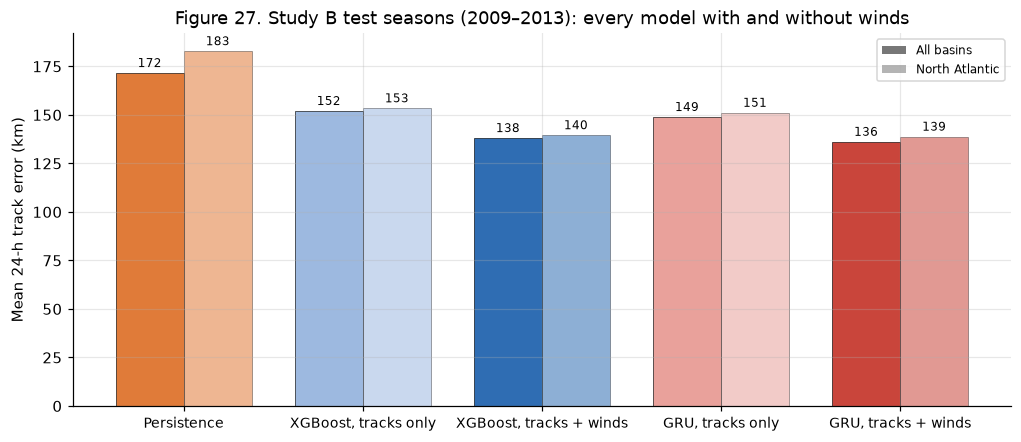

In [7]:
order = list(errors["test"])
colors = ["#E07B39", "#9DB9E0", "#2F6DB3", "#E9A19B", "#C9453B"]
na_te = te["BASIN"].eq("NA").to_numpy()
fig, ax = plt.subplots(figsize=(11, 4.4))
x, w = np.arange(len(order)), 0.38
for k, (mask, lab) in enumerate([(slice(None), "All basins"), (na_te, "North Atlantic")]):
    vals = [errors["test"][m][mask].mean() for m in order]
    ax.bar(x + (k - 0.5) * w, vals, w, color=colors, alpha=1.0 if k == 0 else 0.55, edgecolor="k", lw=0.4)
    for xi, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi, v + 3, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x, order, fontsize=9)
ax.set(ylabel="Mean 24-h track error (km)", title="Figure 27. Study B test seasons (2009–2013): every model with and without winds")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#777", label="All basins"), Patch(facecolor="#777", alpha=0.55, label="North Atlantic")],
          fontsize=8)
savefig(fig, "fig27_studyb_test_results.png")
plt.show()

## 4. Where do the winds help most?

Ever since the EDA, every model has struggled most at higher latitudes, where storms recurve into the
westerlies. That's exactly where the steering flow should matter most, because the turn is driven by the
winds, not by anything in the storm's recent track. Figure 28 checks this on the test seasons, plotting
mean error by 5° latitude band for both models with and without winds.

saved reports/figures/fig28_studyb_by_latitude.png


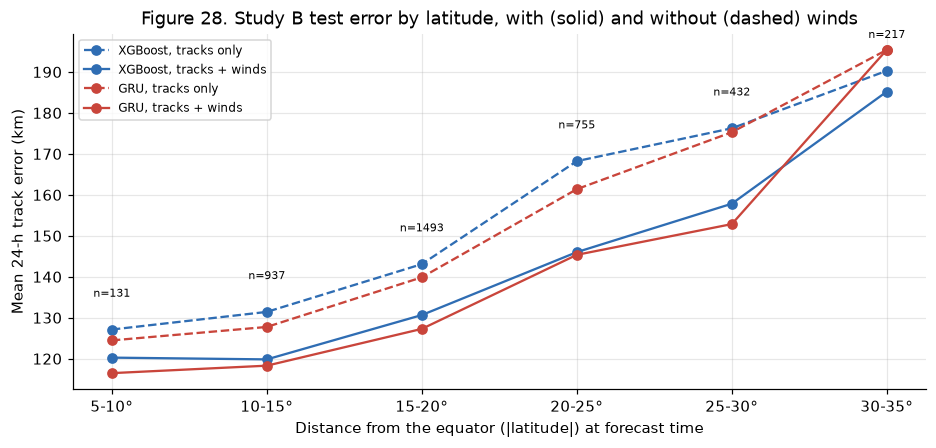

,GRU gain_km,XGBoost gain_km,forecasts
5-10°,8.0,6.9,131
10-15°,9.5,11.6,937
15-20°,12.6,12.4,1493
20-25°,16.0,22.2,755
25-30°,22.4,18.4,432
30-35°,-0.0,5.1,217


In [8]:
show = ["XGBoost, tracks only", "XGBoost, tracks + winds", "GRU, tracks only", "GRU, tracks + winds"]
styles = {"XGBoost, tracks only": ("#2F6DB3", "--"), "XGBoost, tracks + winds": ("#2F6DB3", "-"),
          "GRU, tracks only": ("#C9453B", "--"), "GRU, tracks + winds": ("#C9453B", "-")}
bands = (te["LAT"].abs() // 5 * 5).astype(int)
bb = pd.DataFrame({m: errors["test"][m] for m in show}).groupby(bands).agg(["mean", "size"])
bb = bb[bb[(show[0], "size")] >= 50]
labels = [f"{b}-{b+5}°" for b in bb.index]
fig, ax = plt.subplots(figsize=(10, 4.2))
for m in show:
    c, ls = styles[m]
    ax.plot(labels, bb[(m, "mean")], marker="o", color=c, ls=ls, label=m)
for i, n in enumerate(bb[(show[0], "size")]):
    ax.text(i, bb[(show[0], "mean")].iloc[i] + 8, f"n={n}", ha="center", fontsize=7)
ax.set(xlabel="Distance from the equator (|latitude|) at forecast time", ylabel="Mean 24-h track error (km)",
       title="Figure 28. Study B test error by latitude, with (solid) and without (dashed) winds")
ax.legend(fontsize=8)
savefig(fig, "fig28_studyb_by_latitude.png")
plt.show()
gain_band = pd.DataFrame({"GRU gain_km": bb[("GRU, tracks only", "mean")] - bb[("GRU, tracks + winds", "mean")],
                          "XGBoost gain_km": bb[("XGBoost, tracks only", "mean")] - bb[("XGBoost, tracks + winds", "mean")],
                          "forecasts": bb[(show[0], "size")]}, index=bb.index)
gain_band.index = labels
gain_band.round(1)

So the gains grow with latitude, just as the physics suggests. Near the equator the winds save 7–10 km; between 20° and 30°, where storms begin to recurve, they save **16–22 km** for both models. Those are the forecasts where persistence and the track-only models went most wrong, because the turn comes from the surrounding winds, not from anything in the recent track.

Above 30°, the pattern breaks: the GRU gains nothing and XGBoost only 5 km. That band holds just 217 forecasts, so the numbers are noisy. It's also where storms speed up in the jet stream and begin to turn extratropical, and a 2.5° grid sampled once at the forecast time is too coarse to follow that. Finer winds, or winds from more than one time, would be a natural next step there.

## 5. A storm up close

Finally, let's watch the difference on a real track. To avoid cherry-picking a flattering example, we use the
same rule as notebook 03: the North Atlantic test segment with the biggest total change of direction, since
recurving storms are the hard case. Every 12 hours along its track, Figure 29 draws the 24-hour forecasts
from the GRU with and without winds, next to where the storm actually went.

saved reports/figures/fig29_studyb_example_storm.png


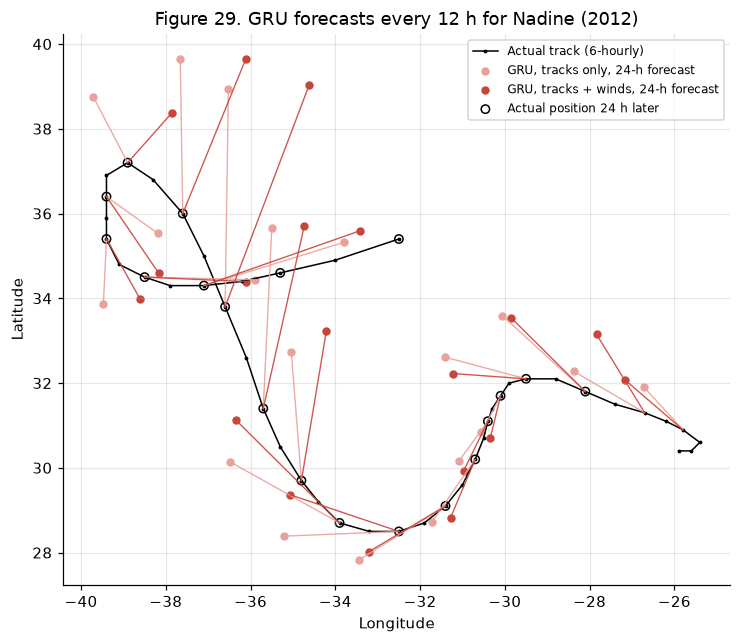

Nadine (2012): 37 forecasts; mean error without winds 175 km, with winds 168 km


In [9]:
gru = {label: np.mean(disp[label]["test"], axis=0) for label in FEATURE_SETS}
for label, key in (("tracks only", "t"), ("tracks + winds", "w")):
    te[f"lat_{key}"], te[f"lon_{key}"] = to_latlon(te["LAT"], te["LON"], gru[label][:, 0], gru[label][:, 1])
te["err_t"], te["err_w"] = errors["test"]["GRU, tracks only"], errors["test"]["GRU, tracks + winds"]

test_na = tracks[tracks["SEG_ID"].isin(te.loc[te["BASIN"].eq("NA"), "SEG_ID"])]
turning = test_na.groupby("SEG_ID")["heading_deg"].agg(lambda h: np.abs(((h.diff() + 180) % 360) - 180).sum())
seg = turning.idxmax()
trk, fc = tracks[tracks["SEG_ID"] == seg], te[te["SEG_ID"] == seg].iloc[::2]
name, season = trk["NAME"].iloc[0].title(), trk["SEASON"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.plot(trk["LON"], trk["LAT"], "k.-", lw=1, ms=3, label="Actual track (6-hourly)")
for key, c, lab in (("t", "#E9A19B", "GRU, tracks only"), ("w", "#C9453B", "GRU, tracks + winds")):
    for _, r in fc.iterrows():
        ax.plot([r["LON"], r[f"lon_{key}"]], [r["LAT"], r[f"lat_{key}"]], color=c, lw=0.9, alpha=0.9)
    ax.scatter(fc[f"lon_{key}"], fc[f"lat_{key}"], color=c, s=20, label=f"{lab}, 24-h forecast")
ax.scatter(fc["lon_true"], fc["lat_true"], facecolor="none", edgecolor="k", s=30, label="Actual position 24 h later")
ax.set(xlabel="Longitude", ylabel="Latitude", aspect="equal", title=f"Figure 29. GRU forecasts every 12 h for {name} ({season})")
ax.legend(fontsize=8, loc="best")
savefig(fig, "fig29_studyb_example_storm.png")
plt.show()
sel = te["SEG_ID"] == seg
print(f"{name} ({season}): {sel.sum()} forecasts; mean error without winds {te.loc[sel, 'err_t'].mean():.0f} km, "
      f"with winds {te.loc[sel, 'err_w'].mean():.0f} km")

As it happens, the rule picked **Nadine (2012)**, one of the most erratic storms in the Atlantic record. Over about three weeks it wandered the open ocean, recurved, stalled and turned back on itself more than once. On its 37 forecasts, the winds trim the GRU's mean error only modestly, from 175 to 168 km, and Figure 29 shows why. Along the smooth stretches both versions do well. At the stalls and sudden reversals, both overshoot, because the steering flow there was weak and shifting. So the example is a fair reminder: the winds help on average, but a storm drifting in a weak, changing flow is hard for any 24-hour forecast built from one snapshot.

## 6. Saving

Last, we save the per-forecast GRU errors for both Study B sets, plus a small configuration file recording
how the Study B networks were built, so the results can be traced and the models reloaded.

In [10]:
keep = ["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME", "split_b"]
pred_out = pd.concat([va[keep], te[keep]], ignore_index=True)
pred_out["err_gru_tracks_only_km"] = np.r_[errors["val"]["GRU, tracks only"], errors["test"]["GRU, tracks only"]]
pred_out["err_gru_tracks_winds_km"] = np.r_[errors["val"]["GRU, tracks + winds"], errors["test"]["GRU, tracks + winds"]]
pred_out.to_csv(PROCESSED / "preds_studyb_gru.csv", index=False)

study_cfg = {"based_on": "round2_config.json", "split": {"train": "1980-2004", "val": "2005-2008", "test": "2009-2013"},
             "feature_sets": FEATURE_SETS, "seeds": SEEDS, "seq_mu": mu.tolist(), "seq_sd": sd.tolist(),
             "y_scale": y_sc.tolist(),
             "test_mean_km": {m: float(e.mean()) for m, e in errors["test"].items()}}
(MODEL_DIR / "studyb_config.json").write_text(json.dumps(study_cfg, indent=2))
print("saved data/processed/preds_studyb_gru.csv, models/studyb_config.json,",
      ", ".join(sorted(p.name for p in MODEL_DIR.glob("studyb_gru_*.pt"))))

saved data/processed/preds_studyb_gru.csv, models/studyb_config.json, studyb_gru_tracks_only_seed2024.pt, studyb_gru_tracks_only_seed42.pt, studyb_gru_tracks_only_seed7.pt, studyb_gru_tracks_winds_seed2024.pt, studyb_gru_tracks_winds_seed42.pt, studyb_gru_tracks_winds_seed7.pt


## Summary

- **The GRU gains as much from the winds as XGBoost did.** On the test seasons its error falls from 149.0 to **136.2 km** (−12.8 km, 95% CI 10.3–15.4), with skill over persistence rising from 13.2% to 20.7%.
- **The wind-aware GRU is Study B's best model** on every measure, though only 1.9 km ahead of the wind-aware XGBoost (CI 0.4–3.4 km).
- **The data mattered more than the model.** Adding steering winds improved error four to six times as much as moving from trees to a recurrent network, and roughly nine times as much as both rounds of tuning combined.
- **The biggest gains come between 20° and 30° latitude** (16–22 km), where storms recurve. Above 30°, where storms enter the jet stream, the coarse once-only snapshot stops helping.

**What Study B means for the project.** Study A's track-only models plateaued near 144 km on validation, and Study B shows a clear, well-tested route past that plateau. A full wind record for 2013–2024 would let the wind-aware GRU be trained on the main split and scored on the locked 2020–2024 test seasons, but NOAA's rate limit blocked that download. So, as planned, the two studies are reported separately: Study A's final test evaluation comes next, and Study B stands as a controlled experiment on its own split.

## References

Chan, J. C. L. (2005). The physics of tropical cyclone motion. *Annual Review of Fluid Mechanics, 37*,
99–128. https://doi.org/10.1146/annurev.fluid.37.061903.175702

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014).
Learning phrase representations using RNN encoder–decoder for statistical machine translation. In
*Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734).
https://doi.org/10.3115/v1/D14-1179

Kalnay, E., Kanamitsu, M., Kistler, R., Collins, W., Deaven, D., Gandin, L., ... Joseph, D. (1996). The
NCEP/NCAR 40-year reanalysis project. *Bulletin of the American Meteorological Society, 77*(3), 437–471.
https://doi.org/10.1175/1520-0477(1996)077<0437:TNYRP>2.0.CO;2

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*